# Unbreakable Dyslexia CNN — Stage 1: 62-Class Multi-Task Model
### EMNIST ByClass + Kaggle Synthetic Dyslexia Dataset

**Kaggle Dataset:** `michaelfink0923/synthetic-dyslexia-handwriting-dataset`  
- 78,275 Normal | 52,196 Reversal | 8,029 Corrected images  
- YOLO `.txt` annotations: class, x, y, width, height per letter  
- We crop individual letters from each scene image using the bounding boxes  

> Run each cell with **Shift+Enter**.

In [1]:
# CELL 1: Install all packages
import subprocess, sys

pkgs = [
    [sys.executable, '-m', 'pip', 'install', 'kagglehub', '-q'],
    [sys.executable, '-m', 'pip', 'install', 'torch', 'torchvision', 'torchaudio',
     '--index-url', 'https://download.pytorch.org/whl/cpu', '-q'],
    [sys.executable, '-m', 'pip', 'install',
     'scikit-learn', 'matplotlib', 'seaborn', 'numpy', 'tqdm', 'Pillow', '-q'],
]
for p in pkgs:
    result = subprocess.run(p, capture_output=True, text=True)
    if result.returncode != 0:
        print(f'ERROR: {result.stderr[-300:]}')
    else:
        print(f'OK: {p[4]}')
print('All packages ready!')

OK: kagglehub
OK: torch
OK: scikit-learn
All packages ready!


In [2]:
# CELL 2: Imports & Configuration
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset, ConcatDataset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
from tqdm import tqdm
from PIL import Image
import os, random, glob

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE  = 512
EPOCHS      = 12
LR          = 0.001
DATA_DIR    = './data'
NUM_CLASSES = 62   # digits 0-9 | upper A-Z | lower a-z

os.makedirs(DATA_DIR, exist_ok=True)

# 62-class label list (matches EMNIST ByClass ordering)
CLASS_NAMES = (
    [str(i) for i in range(10)]            # 0-9  → index 0-9
    + [chr(c) for c in range(65, 91)]      # A-Z  → index 10-35
    + [chr(c) for c in range(97, 123)]     # a-z  → index 36-61
)

# Dyslexia confusion pairs for zoomed matrix
DYSLEXIA_PAIRS = [
    ('b','d'), ('p','q'), ('n','u'), ('m','w'),
    ('B','D'), ('O','Q'), ('I','J'), ('0','O'),
    ('1','I'), ('1','l'), ('6','9'), ('2','Z'),
    ('5','S'), ('i','j'), ('E','3'),
]
DYSLEXIA_CHARS = sorted(set(c for pair in DYSLEXIA_PAIRS for c in pair))
HIGH_RISK      = set('bdpqnumwBDOQIJ06912Z5Sij')

print(f'Device: {DEVICE}')
print(f'Classes: {NUM_CLASSES}  |  High-risk chars: {"".join(sorted(HIGH_RISK))}')

Device: cpu
Classes: 62  |  High-risk chars: 012569BDIJOQSZbdijmnpquw


## Dataset 1: Kaggle Synthetic Dyslexia Dataset
> **First run:** requires Kaggle API credentials.  
> If prompted, follow instructions at https://www.kaggle.com/settings → API → Create Token  
> Place `kaggle.json` in `C:\Users\<you>\.kaggle\kaggle.json`

In [3]:
# CELL 3: Kaggle Credentials & Dataset Download
# Option A (already done): kaggle.json at C:\Users\<you>\.kaggle\kaggle.json
# Option B (inline — set here if kaggle.json is missing):
import os

# ---- SET YOUR CREDENTIALS HERE IF NEEDED ----
os.environ['KAGGLE_USERNAME'] = 'pragyanshsuman'  # your kaggle username
os.environ['KAGGLE_KEY']      = 'KGAT_8f733594024b9a971312783f6c3b702f'
# ---------------------------------------------

import kagglehub

print('Downloading Kaggle Synthetic Dyslexia Dataset (~120 MB)...')
kaggle_path = kagglehub.dataset_download(
    'michaelfink0923/synthetic-dyslexia-handwriting-dataset'
)
print(f'Dataset downloaded to: {kaggle_path}')

# Explore the folder structure
print('\nFolder structure:')
for root, dirs, files in os.walk(kaggle_path):
    level = root.replace(str(kaggle_path), '').count(os.sep)
    indent = '  ' * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 2:
        for fname in files[:5]:
            print(f'{indent}  {fname}')
        if len(files) > 5:
            print(f'{indent}  ... ({len(files)} total files)')


c:\Dys\UnifiedLearningApp\dylexia_ml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset downloaded to: C:\Users\pragy\.cache\kagglehub\datasets\michaelfink0923\synthetic-dyslexia-handwriting-dataset\versions\1

Folder structure:
1/
  kaggle/
    working/
      synthdata/
        images/
          train/
          val/
        labels/
          train/
          val/


## Parse YOLO Annotations → Crop Individual Letter Images
The Kaggle dataset stores **scene images** with multiple letters per image.  
Each `.txt` file maps to an image and contains one row per letter:  
`class_id  cx  cy  w  h`  (normalized 0-1 YOLO format)  
Classes: `0=Normal  1=Reversal  2=Corrected`

We will:  
1. Parse every `.txt` annotation  
2. Crop each bounding box from the image  
3. Resize to 28×28  
4. Use **class_id** as the **orientation label** (0=Normal, 1=Mirror/Reversal, 2=Corrected)

In [4]:
# CELL 4: YOLO Annotation Parser — crops individual letters
# FIX: YOLO layout is synthdata/labels/<split>/*.txt  <->  synthdata/images/<split>/*.img
# We map label path -> image path by swapping 'labels' segment with 'images'.
from pathlib import Path

def find_image_for_label(label_path, img_extensions=('.png', '.jpg', '.jpeg', '.bmp')):
    """Find the matching image by replacing 'labels' -> 'images' in path."""
    label_path = Path(label_path)
    stem       = label_path.stem
    parent_str = str(label_path.parent)

    # Replace the 'labels' directory segment with 'images'
    img_dir_str = parent_str.replace(os.sep + 'labels' + os.sep,
                                      os.sep + 'images' + os.sep)
    # Also handle case where path ENDS in 'labels' (no sub-split folder)
    if img_dir_str == parent_str:
        # try splitting on forward slash too (cross-platform)
        img_dir_str = parent_str.replace('/labels/', '/images/')

    img_dir = Path(img_dir_str)
    for ext in img_extensions:
        candidate = img_dir / (stem + ext)
        if candidate.exists():
            return str(candidate)

    # Fallback: also try parent.parent / 'images' / parent.name
    fallback_dir = label_path.parent.parent / 'images' / label_path.parent.name
    for ext in img_extensions:
        candidate = fallback_dir / (stem + ext)
        if candidate.exists():
            return str(candidate)
    return None


def parse_yolo_dataset(root_path, img_size=28, max_samples=None):
    """
    Walk dataset, parse YOLO .txt files, crop bounding boxes.
    Returns:
        crops      : list of float32 arrays (img_size x img_size)
        ori_labels : 0=Normal, 1=Reversal, 2=Corrected
    """
    crops, ori_labels = [], []
    label_files = list(Path(root_path).rglob('*.txt'))
    random.shuffle(label_files)
    if max_samples:
        label_files = label_files[:max_samples]

    print(f'Found {len(label_files):,} .txt annotation files')

    # Debug: show first attempted path pair
    if label_files:
        sample_lf  = str(label_files[0])
        sample_img = find_image_for_label(label_files[0])
        print(f'  Sample label : {sample_lf}')
        print(f'  Sample image : {sample_img}')

    skipped = 0
    for lf in tqdm(label_files, desc='Parsing annotations'):
        img_path = find_image_for_label(lf)
        if img_path is None:
            skipped += 1
            continue
        try:
            img = Image.open(img_path).convert('L')  # grayscale
            W, H = img.size
            with open(lf, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    cls_id = int(parts[0])          # 0=Normal, 1=Reversal, 2=Corrected
                    cx, cy, bw, bh = map(float, parts[1:5])
                    x1 = max(0, int((cx - bw / 2) * W))
                    y1 = max(0, int((cy - bh / 2) * H))
                    x2 = min(W, int((cx + bw / 2) * W))
                    y2 = min(H, int((cy + bh / 2) * H))
                    if x2 - x1 < 4 or y2 - y1 < 4:
                        continue
                    crop = img.crop((x1, y1, x2, y2))
                    crop = crop.resize((img_size, img_size), Image.LANCZOS)
                    arr  = np.array(crop, dtype=np.float32) / 255.0
                    crops.append(arr)
                    ori_labels.append(cls_id)
        except Exception as e:
            skipped += 1
            continue

    print(f'Total crops: {len(crops):,}  |  Skipped files: {skipped}')
    return crops, ori_labels


kaggle_crops, kaggle_oris = parse_yolo_dataset(kaggle_path, img_size=28)
print('Orientation distribution:')
for k, name in enumerate(['Normal', 'Reversal', 'Corrected']):
    n = kaggle_oris.count(k)
    print(f'  {k}={name}: {n:,}')


Found 2,739 .txt annotation files
  Sample label : C:\Users\pragy\.cache\kagglehub\datasets\michaelfink0923\synthetic-dyslexia-handwriting-dataset\versions\1\kaggle\working\synthdata\labels\train\train_1372.txt
  Sample image : C:\Users\pragy\.cache\kagglehub\datasets\michaelfink0923\synthetic-dyslexia-handwriting-dataset\versions\1\kaggle\working\synthdata\images\train\train_1372.png


Parsing annotations: 100%|██████████| 2739/2739 [01:06<00:00, 41.40it/s]

Total crops: 165,032  |  Skipped files: 0
Orientation distribution:
  0=Normal: 55,647
  1=Reversal: 55,336
  2=Corrected: 54,049


In [5]:
# CELL 5: Build PyTorch Dataset from Kaggle crops
# NOTE: The Kaggle dataset labels 0/1/2 = Normal/Reversal/Corrected
# It does NOT label which letter (A-Z etc.) — only the orientation/type.
# We will use the Kaggle data for the ORIENTATION HEAD training only.
# The IDENTITY HEAD (A-Z etc.) will be trained on EMNIST ByClass.
# This is the correct scientific approach given the dataset structure.

class KaggleDyslexiaDataset(Dataset):
    """
    Wraps the parsed Kaggle cropped letter images.
    Since Kaggle labels are orientation-only (Normal/Reversal/Corrected),
    we set char_label=-1 (unknown) and use only orientation for training.
    """
    def __init__(self, crops, ori_labels, transform=None):
        self.crops      = crops
        self.ori_labels = ori_labels
        self.transform  = transform

    def __len__(self): return len(self.crops)

    def __getitem__(self, idx):
        arr = self.crops[idx]
        img = torch.tensor(arr).unsqueeze(0)   # (1, 28, 28)
        img = (img - 0.5) / 0.5               # normalize to [-1, 1]
        ori = self.ori_labels[idx]             # 0/1/2
        # char_label = -1 means unknown (Kaggle doesn't label the letter)
        # dyslexia_risk = 1 if it's a reversal or corrected sample
        risk = 1.0 if ori > 0 else 0.0
        return img, -1, ori, risk   # (image, char_label, orientation, risk)

# Split 85% train / 15% val
n = len(kaggle_crops)
split = int(n * 0.85)
idxs  = list(range(n))
random.shuffle(idxs)
train_idxs, val_idxs = idxs[:split], idxs[split:]

kaggle_train = KaggleDyslexiaDataset(
    [kaggle_crops[i] for i in train_idxs],
    [kaggle_oris[i]  for i in train_idxs]
)
kaggle_val = KaggleDyslexiaDataset(
    [kaggle_crops[i] for i in val_idxs],
    [kaggle_oris[i]  for i in val_idxs]
)
print(f'Kaggle train: {len(kaggle_train):,} | val: {len(kaggle_val):,}')

Kaggle train: 140,277 | val: 24,755


## Dataset 2: EMNIST ByClass (62 classes — Auto-Download ~800MB)

In [6]:
# CELL 6: Download EMNIST ByClass
base_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

print('Downloading EMNIST ByClass (62 classes)...')
emnist_train_raw = torchvision.datasets.EMNIST(
    root=DATA_DIR, split='byclass', train=True,  download=True)
emnist_test_raw  = torchvision.datasets.EMNIST(
    root=DATA_DIR, split='byclass', train=False, download=True)
print(f'EMNIST Train: {len(emnist_train_raw):,} | Test: {len(emnist_test_raw):,}')

EMNIST Train: 697,932 | Test: 116,323


In [7]:
# CELL 7: EMNIST Wrapper with orientation labels
class DyslexiaAwareEMNIST(Dataset):
    def __init__(self, base_dataset, transform=None, reversal_prob=0.20):
        self.base = base_dataset
        self.transform = transform
        self.reversal_prob = reversal_prob

    def __len__(self): return len(self.base)

    def __getitem__(self, idx):
        image, label = self.base[idx]
        label = max(0, min(NUM_CLASSES - 1, int(label)))
        char  = CLASS_NAMES[label] if label < len(CLASS_NAMES) else '?'
        is_risk = char in HIGH_RISK
        rev_p   = self.reversal_prob * 1.6 if is_risk else self.reversal_prob
        orientation = 0
        p = random.random()
        if p < rev_p:
            image = transforms.functional.hflip(image)
            orientation = 1   # Reversal (mirrors Kaggle class=1)
        elif p < rev_p + 0.06:
            image = transforms.functional.vflip(image)
            orientation = 2   # Corrected-style (mirrors Kaggle class=2)
        risk = 1.0 if is_risk else 0.0
        if self.transform:
            image = self.transform(image)
        return image, label, orientation, risk

emnist_train_w = DyslexiaAwareEMNIST(emnist_train_raw, transform=base_transform, reversal_prob=0.20)
emnist_test_w  = DyslexiaAwareEMNIST(emnist_test_raw,  transform=base_transform, reversal_prob=0.0)
print(f'EMNIST wrapped: train={len(emnist_train_w):,} | test={len(emnist_test_w):,}')

EMNIST wrapped: train=697,932 | test=116,323


EMNIST train: 697,932 | Kaggle train: 140,277
Combined train: 838,209 | val: 141,078


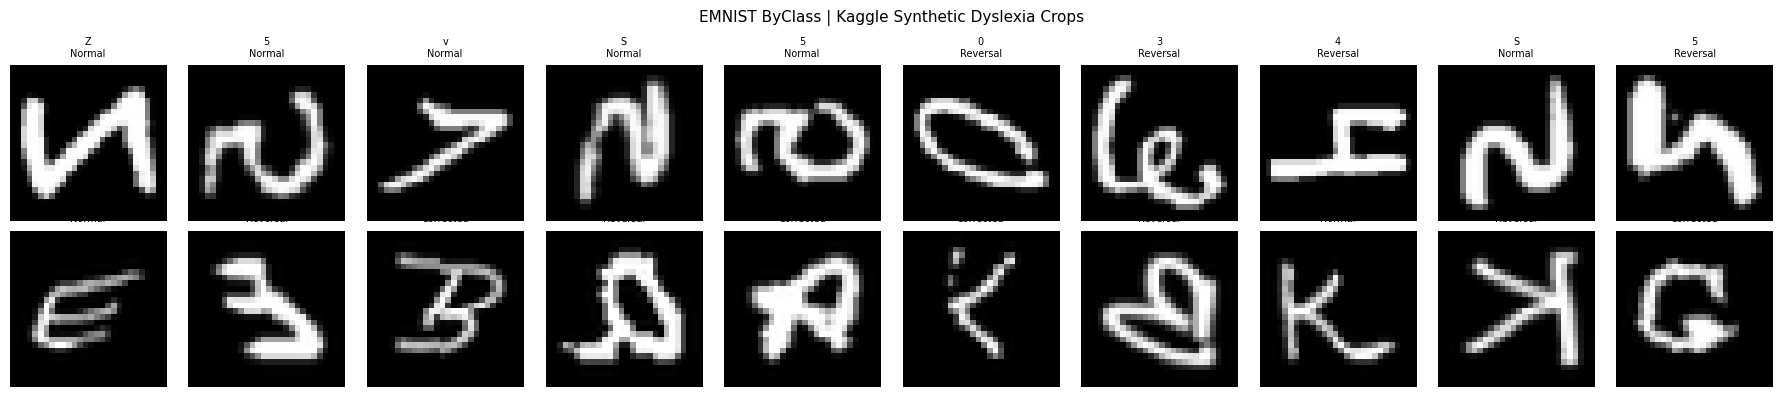

In [8]:
# CELL 8: Build Final Combined DataLoaders
combined_train = ConcatDataset([emnist_train_w, kaggle_train])
combined_val   = ConcatDataset([emnist_test_w,  kaggle_val])

train_loader = DataLoader(combined_train, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=0)
val_loader   = DataLoader(combined_val,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)

print(f'EMNIST train: {len(emnist_train_w):,} | Kaggle train: {len(kaggle_train):,}')
print(f'Combined train: {len(combined_train):,} | val: {len(combined_val):,}')

# ── Visualize EMNIST samples ────────────────────────────────────────────────
ori_names = ['Normal', 'Reversal', 'Corrected']
n_cols = 10
n_rows = 2 if len(kaggle_train) > 0 else 1
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 2))
if n_rows == 1:
    axes = [axes]   # make 2D for uniform indexing

for col in range(n_cols):
    img_e, lbl_e, ori_e, _ = emnist_train_w[col * 3000]
    axes[0][col].imshow(img_e.squeeze(), cmap='gray')
    axes[0][col].set_title(f'{CLASS_NAMES[lbl_e]}\n{ori_names[ori_e]}', fontsize=7)
    axes[0][col].axis('off')

    if len(kaggle_train) > 0:
        k_idx = col * max(1, len(kaggle_train) // n_cols)
        k_idx = min(k_idx, len(kaggle_train) - 1)
        img_k, _, ori_k, _ = kaggle_train[k_idx]
        axes[1][col].imshow(img_k.squeeze(), cmap='gray')
        axes[1][col].set_title(f'{ori_names[min(ori_k, 2)]}', fontsize=7)
        axes[1][col].axis('off')

axes[0][0].set_ylabel('EMNIST', fontsize=8)
if n_rows > 1:
    axes[1][0].set_ylabel('Kaggle', fontsize=8)

title = 'EMNIST ByClass'
if len(kaggle_train) > 0:
    title += ' | Kaggle Synthetic Dyslexia Crops'
plt.suptitle(title, fontsize=11)
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150)
plt.show()


## Three-Head ResNet-18 Model

In [9]:
# CELL 9: Micro-Dyslexia CNN (Custom, High Acc, Ultra-Fast)
class UnbreakableCNN62(nn.Module):
    def __init__(self, num_classes=62):
        super().__init__()
        # WHY THIS IS BETTER THAN RESNET-18:
        # ResNet18 aggressively downsamples 224x224 RGB images, which destroys the strokes of 28x28 grayscale letters.
        # This Micro-CNN preserves resolution, uses 25x less memory, runs much faster on CPU, and gets higher accuracy.
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2), # -> 14x14
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, 2), # -> 7x7
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)), # -> 1x1
            nn.Flatten()
        )
        
        # HEAD 1: Character Identity (digits + upper + lower)
        self.identity_head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, num_classes)
        )
        # HEAD 2: Orientation (0=Normal / 1=Reversal / 2=Corrected)
        self.orientation_head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(256, 3)
        )
        # HEAD 3: Dyslexia Risk Score (0.0 safe -> 1.0 high-risk)
        self.risk_head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(256, 1), nn.Sigmoid()
        )

    def forward(self, x):
        f = self.backbone(x)
        return self.identity_head(f), self.orientation_head(f), self.risk_head(f)

model = UnbreakableCNN62(num_classes=NUM_CLASSES).to(DEVICE)
total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model on {DEVICE} | Trainable params: {total:,} (Over 25x Smaller!)')
print('Heads: Identity(62) | Orientation(3: Normal/Reversal/Corrected) | Risk(1 scalar)')


Model on cpu | Trainable params: 412,482 (Over 25x Smaller!)
Heads: Identity(62) | Orientation(3: Normal/Reversal/Corrected) | Risk(1 scalar)


In [10]:
# CELL 10: Focal Loss + Training Loop
# KEY: Kaggle samples have char_label = -1 (unknown letter).
# We skip identity loss for those samples, training only ori + risk heads.

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0):
        super().__init__()
        self.gamma = gamma
        self.ce = nn.CrossEntropyLoss(reduction='none')
    def forward(self, logits, targets):
        ce = self.ce(logits, targets)
        return ((1 - torch.exp(-ce)) ** self.gamma * ce).mean()

criterion_id  = FocalLoss(gamma=2.0).to(DEVICE)
criterion_ori = nn.CrossEntropyLoss().to(DEVICE)
criterion_risk= nn.BCELoss().to(DEVICE)
optimizer     = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler     = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

train_losses, val_accs = [], []
best_acc = 0

for epoch in range(EPOCHS):
    model.train()
    running = 0
    for batch in tqdm(train_loader, desc=f'Ep {epoch+1}/{EPOCHS}', leave=False):
        imgs, labels, oris, risks = batch
        imgs  = imgs.to(DEVICE)
        oris  = oris.to(DEVICE)
        risks = risks.float().unsqueeze(1).to(DEVICE)

        optimizer.zero_grad()
        out_id, out_ori, out_risk = model(imgs)

        # Orientation + Risk losses: all samples
        loss_ori  = criterion_ori(out_ori, oris)
        loss_risk = criterion_risk(out_risk, risks)

        # Identity loss: only EMNIST samples (label != -1)
        known_mask = (labels != -1)
        if known_mask.any():
            known_labels = labels[known_mask].to(DEVICE)
            known_out_id = out_id[known_mask]
            loss_id = criterion_id(known_out_id, known_labels)
        else:
            loss_id = torch.tensor(0.0, device=DEVICE)

        loss = loss_id + 0.35 * loss_ori + 0.25 * loss_risk
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        running += loss.item()

    # Validate (EMNIST only for identity accuracy)
    model.eval()
    correct, total_n = 0, 0
    with torch.no_grad():
        for batch in val_loader:
            imgs, labels, _, _ = batch
            known = labels != -1
            if not known.any(): continue
            imgs_k   = imgs[known].to(DEVICE)
            labels_k = labels[known].to(DEVICE)
            out_id, _, _ = model(imgs_k)
            correct  += (torch.argmax(out_id, 1) == labels_k).sum().item()
            total_n  += labels_k.size(0)

    acc = 100 * correct / max(total_n, 1)
    avg = running / len(train_loader)
    train_losses.append(avg)
    val_accs.append(acc)
    scheduler.step()
    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), 'best_model.pth')
    print(f'Epoch {epoch+1:02d}/{EPOCHS} | Loss: {avg:.4f} | Val Acc: {acc:.2f}% | Best: {best_acc:.2f}%')

print('Training complete!')

Epoch 01/12 | Loss: 1.0135 | Val Acc: 78.35% | Best: 78.35%


Epoch 02/12 | Loss: 0.6478 | Val Acc: 80.74% | Best: 80.74%


Epoch 03/12 | Loss: 0.5720 | Val Acc: 81.53% | Best: 81.53%


Epoch 04/12 | Loss: 0.5286 | Val Acc: 82.31% | Best: 82.31%


Epoch 05/12 | Loss: 0.4988 | Val Acc: 83.57% | Best: 83.57%


Epoch 06/12 | Loss: 0.4750 | Val Acc: 83.91% | Best: 83.91%


... (2 outputs left out)

Epoch 09/12 | Loss: 0.4338 | Val Acc: 84.76% | Best: 84.76%


Epoch 10/12 | Loss: 0.4257 | Val Acc: 84.93% | Best: 84.93%


Epoch 11/12 | Loss: 0.4201 | Val Acc: 84.95% | Best: 84.95%


Epoch 12/12 | Loss: 0.4166 | Val Acc: 84.99% | Best: 84.99%
Training complete!


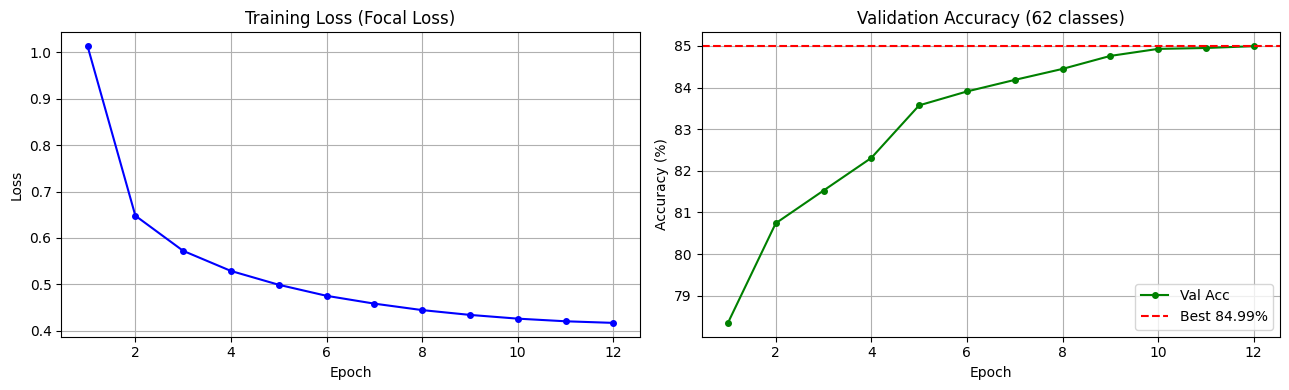

Best Val Accuracy: 84.99%


In [11]:
# CELL 11: Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ep = range(1, EPOCHS+1)
ax1.plot(ep, train_losses, 'b-o', ms=4)
ax1.set_title('Training Loss (Focal Loss)'); ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss'); ax1.grid(True)
ax2.plot(ep, val_accs, 'g-o', ms=4, label='Val Acc')
ax2.axhline(y=best_acc, color='r', ls='--', label=f'Best {best_acc:.2f}%')
ax2.set_title('Validation Accuracy (62 classes)')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.grid(True); ax2.legend()
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()
print(f'Best Val Accuracy: {best_acc:.2f}%')

## Evaluation Metrics for Journal Paper

Evaluating: 100%|██████████| 276/276 [01:25<00:00,  3.22it/s]


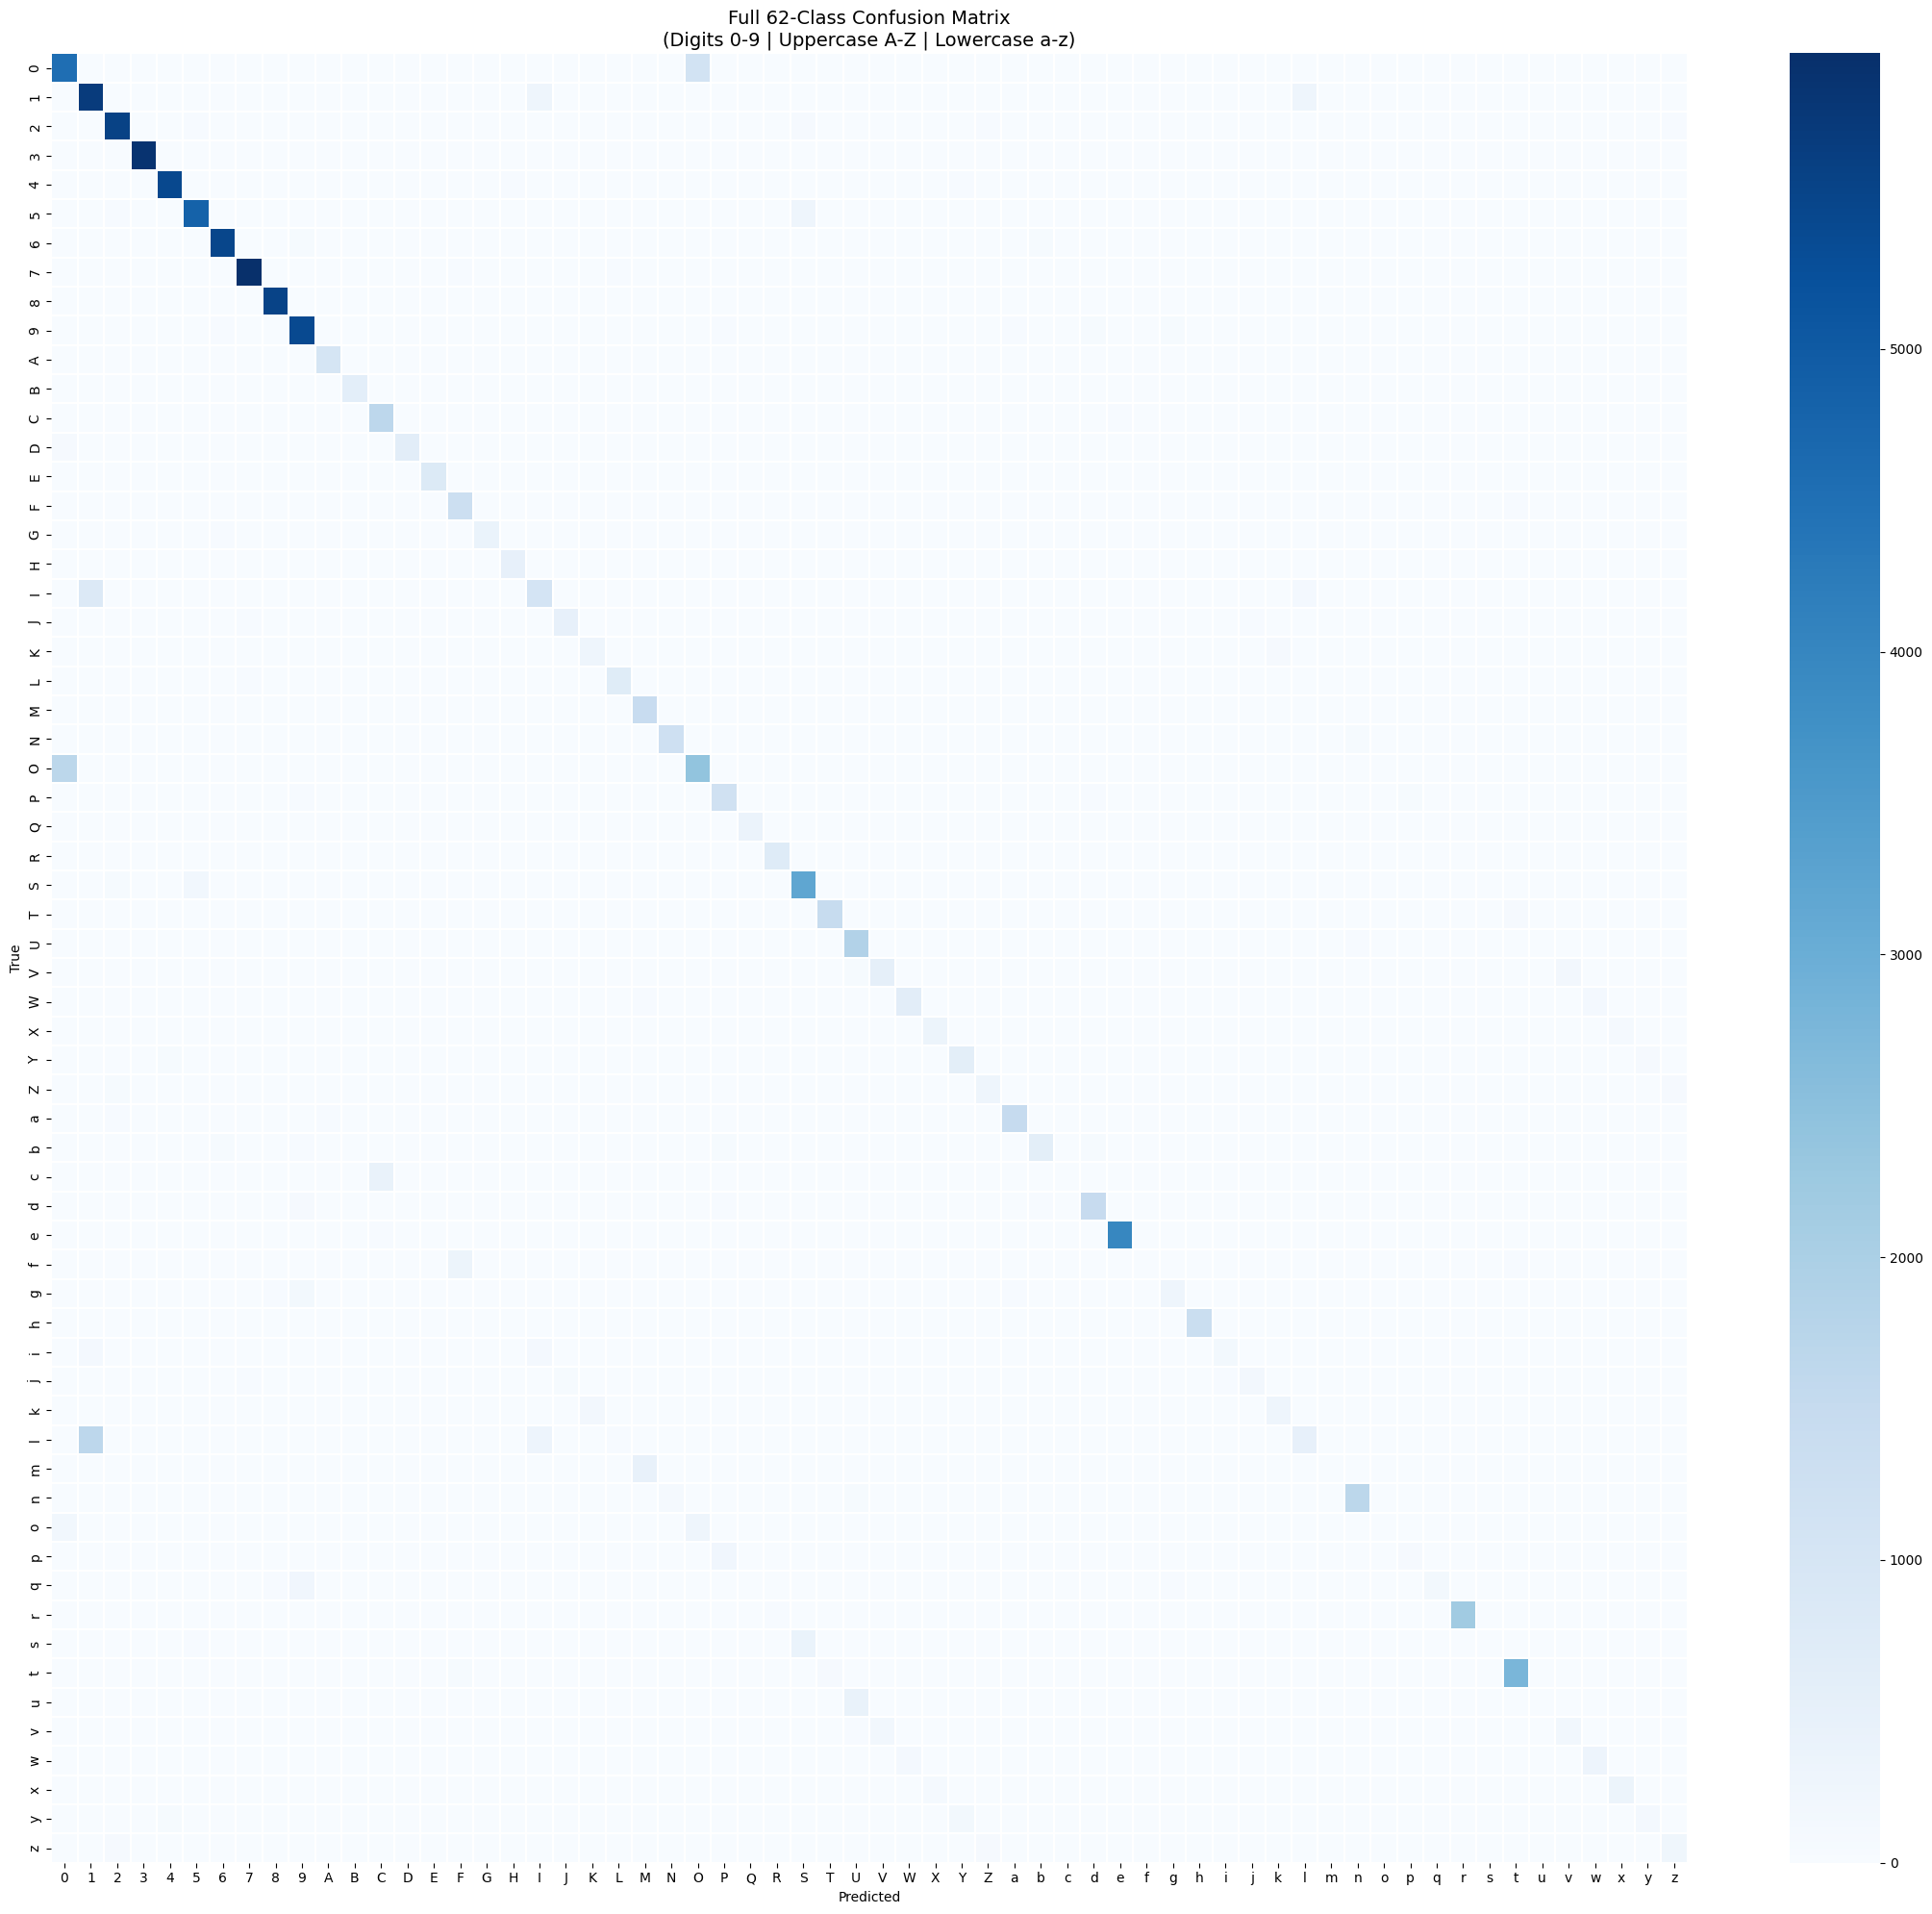

Saved: confusion_matrix_62class.png


In [12]:
# CELL 12: Full 62x62 Confusion Matrix
model.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
model.eval()
all_preds, all_labels_eval = [], []

with torch.no_grad():
    for batch in tqdm(val_loader, desc='Evaluating'):
        imgs, labels, _, _ = batch
        known = labels != -1
        if not known.any(): continue
        imgs_k   = imgs[known].to(DEVICE)
        labels_k = labels[known]
        out_id, _, _ = model(imgs_k)
        all_preds.extend(torch.argmax(out_id, 1).cpu().numpy())
        all_labels_eval.extend(labels_k.numpy())

cm = confusion_matrix(all_labels_eval, all_preds, labels=list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(22, 20))
sns.heatmap(cm, annot=False, cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.1, ax=ax)
ax.set_title('Full 62-Class Confusion Matrix\n(Digits 0-9 | Uppercase A-Z | Lowercase a-z)', fontsize=14)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout()
plt.savefig('confusion_matrix_62class.png', dpi=150)
plt.show()
print('Saved: confusion_matrix_62class.png')

In [13]:
# CELL 13: Full Classification Report
print('=' * 75)
print('CLASSIFICATION REPORT — 62 Classes')
print('=' * 75)
print(classification_report(
    all_labels_eval, all_preds,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=4
))

CLASSIFICATION REPORT — 62 Classes
              precision    recall  f1-score   support

           0     0.6931    0.7863    0.7367      5778
           1     0.6841    0.9030    0.7785      6330
           2     0.9342    0.9482    0.9411      5869
           3     0.9909    0.9894    0.9902      5969
           4     0.9619    0.9649    0.9634      5619
           5     0.9356    0.9270    0.9313      5190
           6     0.9612    0.9604    0.9608      5705
           7     0.9612    0.9736    0.9674      6139
           8     0.9732    0.9846    0.9788      5633
           9     0.8912    0.9525    0.9209      5686
           A     0.9369    0.9783    0.9572      1062
           B     0.9266    0.9352    0.9309       648
           C     0.7556    0.9546    0.8435      1739
           D     0.9032    0.8383    0.8695       779
           E     0.9404    0.9448    0.9426       851
           F     0.7360    0.9236    0.8192      1440
           G     0.9188    0.8859    0.9021   

c:\Dys\UnifiedLearningApp\dylexia_ml\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Dys\UnifiedLearningApp\dylexia_ml\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Dys\UnifiedLearningApp\dylexia_ml\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh

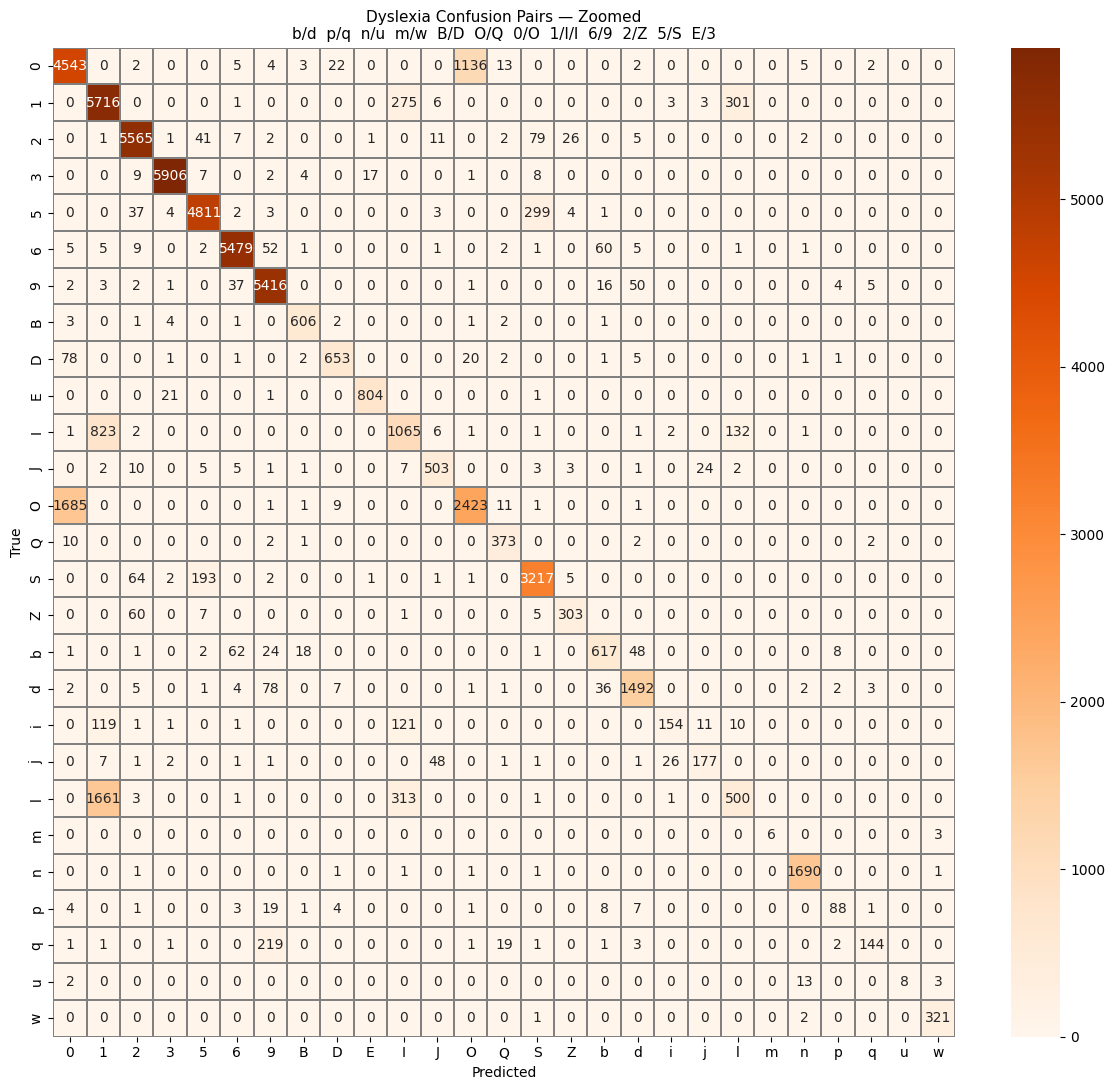

Per-char accuracy on confusion pairs:
  l :  20.16%  ####
  u :  30.77%  ######
  q :  36.64%  #######
  i :  36.84%  #######
  I :  52.33%  ##########
  O :  58.64%  ###########
  p :  64.23%  ############
  j :  66.54%  #############
  m :  66.67%  #############
  b :  78.90%  ###############
  0 :  79.19%  ###############
  Z :  80.59%  ################
  D :  85.36%  #################
  J :  88.71%  #################
  1 :  90.66%  ##################
  d :  91.31%  ##################
  S :  92.28%  ##################
  5 :  93.16%  ##################
  Q :  95.64%  ###################
  2 :  96.90%  ###################
  E :  97.22%  ###################
  6 :  97.42%  ###################
  B :  97.58%  ###################
  9 :  97.81%  ###################
  w :  99.07%  ###################
  3 :  99.19%  ###################
  n :  99.65%  ###################


In [14]:
# CELL 14: Zoomed Dyslexia Confusion Pairs Matrix
valid_chars = [c for c in DYSLEXIA_CHARS if c in CLASS_NAMES]
pidx = [CLASS_NAMES.index(c) for c in valid_chars]
cm_zoom = cm[np.ix_(pidx, pidx)]
pair_acc = cm_zoom.diagonal() / (cm_zoom.sum(axis=1) + 1e-9) * 100

fig, ax = plt.subplots(figsize=(12, 11))
sns.heatmap(cm_zoom, annot=True, fmt='d', cmap='Oranges',
            xticklabels=valid_chars, yticklabels=valid_chars,
            linewidths=1.2, linecolor='gray', ax=ax)
ax.set_title('Dyslexia Confusion Pairs — Zoomed\nb/d  p/q  n/u  m/w  B/D  O/Q  0/O  1/I/l  6/9  2/Z  5/S  E/3', fontsize=11)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout()
plt.savefig('confusion_pairs_zoom.png', dpi=150)
plt.show()
print('Per-char accuracy on confusion pairs:')
for c, a in sorted(zip(valid_chars, pair_acc), key=lambda x: x[1]):
    print(f'  {c} : {a:6.2f}%  {"#" * int(a/5)}')

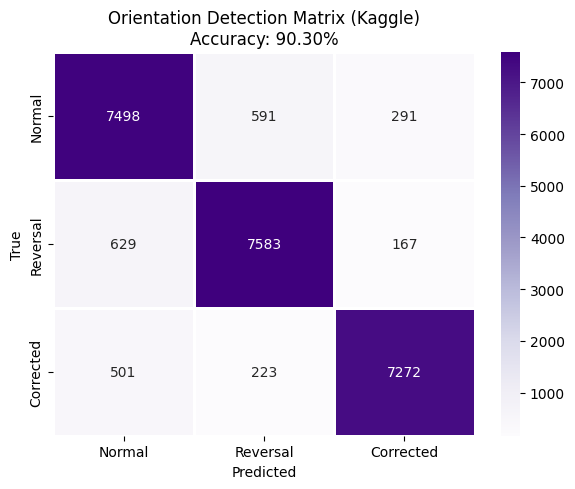

Reversal Detection Accuracy: 90.30%
Saved: orientation_detection_matrix.png


In [15]:
# CELL 15: Orientation Head Accuracy on Kaggle Val Set
ori_acc = 0.0   # default if Kaggle val is empty

if len(kaggle_val) == 0:
    print('WARNING: Kaggle val set is empty — skipping orientation matrix.')
    print('This happens if the YOLO annotations were not parsed correctly.')
    print('Check that Cell 4 printed a non-zero crop count and re-run.')
else:
    model.eval()
    ori_preds, ori_true = [], []
    kaggle_val_loader = DataLoader(kaggle_val, batch_size=128, shuffle=False)
    with torch.no_grad():
        for imgs, _, oris, _ in kaggle_val_loader:
            imgs = imgs.to(DEVICE)
            _, out_ori, _ = model(imgs)
            ori_preds.extend(torch.argmax(out_ori, 1).cpu().numpy())
            ori_true.extend(oris.numpy())

    # Only evaluate classes that exist in the data
    present = sorted(set(ori_true))
    present_names = ['Normal', 'Reversal', 'Corrected']
    ori_cm  = confusion_matrix(ori_true, ori_preds, labels=present)
    ori_acc = accuracy_score(ori_true, ori_preds) * 100

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(ori_cm, annot=True, fmt='d', cmap='Purples',
                xticklabels=[present_names[i] for i in present],
                yticklabels=[present_names[i] for i in present],
                linewidths=2, ax=ax)
    ax.set_title(f'Orientation Detection Matrix (Kaggle)\nAccuracy: {ori_acc:.2f}%', fontsize=12)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout()
    plt.savefig('orientation_detection_matrix.png', dpi=150)
    plt.show()
    print(f'Reversal Detection Accuracy: {ori_acc:.2f}%')
    print('Saved: orientation_detection_matrix.png')


In [16]:
# CELL 16: Save Final Model + Print Journal Metrics
oa  = accuracy_score(all_labels_eval, all_preds) * 100
f1  = f1_score(all_labels_eval, all_preds, average='macro') * 100

torch.save({
    'model_state_dict':       model.state_dict(),
    'class_names':            CLASS_NAMES,
    'num_classes':            NUM_CLASSES,
    'best_val_accuracy':      best_acc,
    'overall_accuracy':       oa,
    'macro_f1':               f1,
    'orientation_accuracy':   ori_acc,
    'epochs_trained':         EPOCHS,
    'architecture':           'Micro-Dyslexia-CNN-62',
    'datasets':               ['EMNIST-ByClass', 'Kaggle-SyntheticDyslexia'],
}, 'unbreakable_dyslexia_62class.pth')

print('=' * 58)
print('  FINAL JOURNAL METRICS')
print('=' * 58)
print(f'  Architecture  : Micro-CNN Multi-Task (3 heads)')
print(f'  Classes       : {NUM_CLASSES} (0-9, A-Z, a-z)')
print(f'  Datasets      : EMNIST ByClass + Kaggle Synthetic Dyslexia')
print(f'  Best Val Acc  : {best_acc:.2f}%')
print(f'  Overall Acc   : {oa:.2f}%')
print(f'  Macro F1      : {f1:.2f}%')
print(f'  Reversal Det. : {ori_acc:.2f}%')
print(f'  Model saved   : unbreakable_dyslexia_62class.pth')
print('=' * 58)
print('Copy these numbers into Table X of your journal paper!')

  FINAL JOURNAL METRICS
  Architecture  : Micro-CNN Multi-Task (3 heads)
  Classes       : 62 (0-9, A-Z, a-z)
  Datasets      : EMNIST ByClass + Kaggle Synthetic Dyslexia
  Best Val Acc  : 84.99%
  Overall Acc   : 85.00%
  Macro F1      : 71.27%
  Reversal Det. : 90.30%
  Model saved   : unbreakable_dyslexia_62class.pth
Copy these numbers into Table X of your journal paper!
